# Modelagem neural — MLP + Optuna e LSTM + Grid Search

Este notebook executa os quatro experimentos científicos definidos para o paper: MLP e LSTM sobre os conjuntos simples (16 atributos) e completo (36 atributos). O teste final permanece isolado durante toda a seleção de hiperparâmetros.

> **Custo computacional:** as configurações padrão abaixo executam o protocolo científico completo. Cada seção de treinamento salva seus artefatos imediatamente ao terminar.

## 1. Configuração e dependências

In [ ]:
import json
import platform
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import optuna
import pandas as pd
import sklearn
import torch

from src.modeling.lstm_grid_search import (
    DEFAULT_LSTM_PARAM_GRID,
    DEFAULT_LSTM_PARAMS,
    DEFAULT_LSTM_SEEDS,
)
from src.modeling.lstm_training import (
    save_lstm_experiment_artifacts,
    train_lstm_experiment,
)
from src.modeling.mlp_optuna import (
    DEFAULT_MAX_EPOCHS,
    DEFAULT_MLP_SEEDS,
    DEFAULT_OPTUNA_TRIALS,
    DEFAULT_PRUNING_INTERVAL,
    DEFAULT_SAMPLER_SEED,
)
from src.modeling.mlp_training import (
    save_mlp_experiment_artifacts,
    train_mlp_experiment,
)
from src.modeling.modeling import (
    plot_model_comparison,
    prepare_modeling_artifact_directories,
)
from src.modeling.neural_experiments import (
    build_neural_experiment_matrix,
    prepare_neural_feature_sets,
)

OUTPUT_DIR = Path('results/modeling')
ARTIFACT_DIRS = prepare_modeling_artifact_directories(OUTPUT_DIR)

TEST_DAYS = 365
INITIAL_TRAIN_DAYS = 730
VALIDATION_DAYS = 180
STEP_DAYS = 180

SEEDS = tuple(DEFAULT_MLP_SEEDS)
DEVICE = None  # None seleciona CUDA quando disponível, senão CPU.

MLP_N_TRIALS = DEFAULT_OPTUNA_TRIALS
MLP_MAX_EPOCHS = DEFAULT_MAX_EPOCHS
MLP_PRUNING_INTERVAL = DEFAULT_PRUNING_INTERVAL
MLP_SAMPLER_SEED = DEFAULT_SAMPLER_SEED

LSTM_PARAM_GRID = {
    name: tuple(values)
    for name, values in DEFAULT_LSTM_PARAM_GRID.items()
}

neural_results = {}
artifact_paths = {}

print(f'Python: {platform.python_version()}')
print(f'PyTorch: {torch.__version__}')
print(f'Optuna: {optuna.__version__}')
print(f'scikit-learn: {sklearn.__version__}')
print(f'Device: {DEVICE or ("cuda" if torch.cuda.is_available() else "cpu")}')

## 2. Preparação comum dos experimentos

Os dois conjuntos são alinhados por data e alvo. O holdout e os folds expansivos são compartilhados pelas quatro combinações.

In [2]:
feature_sets = prepare_neural_feature_sets(
    test_days=TEST_DAYS,
    initial_train_days=INITIAL_TRAIN_DAYS,
    validation_days=VALIDATION_DAYS,
    step_days=STEP_DAYS,
)
experiments = build_neural_experiment_matrix(feature_sets=feature_sets)

dataset_summary = pd.DataFrame([
    {
        'Dataset': name,
        'Rows': len(data['full_dataset']),
        'DevelopmentRows': len(data['development_dataset']),
        'TestRows': len(data['test_dataset']),
        'Predictors': data['input_size'],
        'Folds': len(data['splits']),
    }
    for name, data in feature_sets.items()
])
display(dataset_summary)
display(feature_sets['simple']['holdout_summary'])
display(feature_sets['simple']['validation_summary'])

,Dataset,Rows,DevelopmentRows,TestRows,Predictors,Folds
0,simple,1499,1140,359,16,5
1,complete,1499,1140,359,36,5


,Development_start,Development_end,Development_rows,Test_start,Test_end,Test_rows,Test_calendar_days
0,2020-02-08 00:00:00-03:00,2024-05-16 00:00:00-03:00,1140,2024-05-17 00:00:00-03:00,2025-05-16 00:00:00-03:00,359,365


,Fold,Train_start,Train_end,Validation_start,Validation_end,Train_rows,Validation_rows
0,1,2020-02-08 00:00:00-03:00,2022-02-06 00:00:00-03:00,2022-02-07 00:00:00-03:00,2022-07-27 00:00:00-03:00,585,138
1,2,2020-02-08 00:00:00-03:00,2022-07-27 00:00:00-03:00,2022-10-06 00:00:00-03:00,2023-02-01 00:00:00-03:00,723,107
2,3,2020-02-08 00:00:00-03:00,2023-02-01 00:00:00-03:00,2023-02-02 00:00:00-03:00,2023-07-31 00:00:00-03:00,830,130
3,4,2020-02-08 00:00:00-03:00,2023-07-31 00:00:00-03:00,2023-08-01 00:00:00-03:00,2024-01-27 00:00:00-03:00,960,79
4,5,2020-02-08 00:00:00-03:00,2024-01-27 00:00:00-03:00,2024-01-28 00:00:00-03:00,2024-05-16 00:00:00-03:00,1039,101


## 3. Persistência do protocolo experimental

Esta etapa registra divisões, versões, sementes e orçamentos antes dos treinamentos.

In [3]:
feature_sets['simple']['holdout_summary'].to_csv(
    ARTIFACT_DIRS['validation'] / 'final_holdout.csv',
    index=False,
)
feature_sets['simple']['validation_summary'].to_csv(
    ARTIFACT_DIRS['validation'] / 'validation_windows.csv',
    index=False,
)

protocol = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'target': 'recurrences_lt_30m',
    'test_days': TEST_DAYS,
    'initial_train_days': INITIAL_TRAIN_DAYS,
    'validation_days': VALIDATION_DAYS,
    'step_days': STEP_DAYS,
    'seeds': list(SEEDS),
    'device_request': DEVICE,
    'feature_counts': {
        name: data['input_size']
        for name, data in feature_sets.items()
    },
    'mlp': {
        'method': 'Optuna TPE with median pruning',
        'n_trials': MLP_N_TRIALS,
        'max_epochs': MLP_MAX_EPOCHS,
        'pruning_interval': MLP_PRUNING_INTERVAL,
        'sampler_seed': MLP_SAMPLER_SEED,
        'selection_metric': 'mean expanding-window MAE',
    },
    'lstm': {
        'method': 'Grid Search',
        'fixed_parameters': DEFAULT_LSTM_PARAMS,
        'parameter_grid': {
            name: list(values)
            for name, values in LSTM_PARAM_GRID.items()
        },
        'selection_metric': 'mean expanding-window MAE',
    },
    'versions': {
        'python': platform.python_version(),
        'torch': torch.__version__,
        'optuna': optuna.__version__,
        'pandas': pd.__version__,
        'scikit_learn': sklearn.__version__,
    },
}
protocol_path = ARTIFACT_DIRS['metadata'] / 'neural_experiment_protocol.json'
protocol_path.write_text(
    json.dumps(protocol, indent=2, ensure_ascii=False),
    encoding='utf-8',
)
print(f'Protocol saved to: {protocol_path}')

Protocol saved to: results\modeling\metadata\neural_experiment_protocol.json


## 4. MLP + Optuna — conjunto simples

In [4]:
mlp_simple = train_mlp_experiment(
    experiments['mlp_simple'],
    n_trials=MLP_N_TRIALS,
    seeds=SEEDS,
    max_epochs=MLP_MAX_EPOCHS,
    pruning_interval=MLP_PRUNING_INTERVAL,
    sampler_seed=MLP_SAMPLER_SEED,
    device=DEVICE,
)
neural_results['mlp_simple'] = mlp_simple
artifact_paths['mlp_simple'] = save_mlp_experiment_artifacts(
    mlp_simple,
    OUTPUT_DIR,
)
display(mlp_simple['trials_summary'].query("State == 'COMPLETE'").sort_values('Value').head(10))
display(mlp_simple['seed_metrics'])
display(pd.DataFrame([mlp_simple['test_metrics']]))

,Trial,State,Value,DurationSeconds,Parameters,ResolvedParameters,CompletedRuns,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_R2_mean,CV_PoissonDeviance_mean,TrainingSeconds,InferenceSeconds,TotalRunSeconds,PrunedAtStep
12,12,COMPLETE,12.124196,23.891265,"{""batch_size"": 64, ""dropout"": 0.1, ""hidden_siz...","{""batch_size"": 64, ""dropout"": 0.1, ""hidden_siz...",15,12.124196,6.088558,24.796053,-0.479083,73.197569,23.838864,0.011993,23.850856,NaN
27,27,COMPLETE,12.137431,24.245446,"{""batch_size"": 64, ""dropout"": 0.1, ""hidden_siz...","{""batch_size"": 64, ""dropout"": 0.1, ""hidden_siz...",15,12.137431,6.067107,24.793673,-0.474646,73.737365,24.192555,0.012458,24.205013,NaN
26,26,COMPLETE,12.154159,24.013775,"{""batch_size"": 64, ""dropout"": 0.2, ""hidden_siz...","{""batch_size"": 64, ""dropout"": 0.2, ""hidden_siz...",15,12.154159,6.038693,24.788885,-0.473834,46.832175,23.960959,0.011994,23.972953,NaN
5,5,COMPLETE,12.195027,24.448868,"{""batch_size"": 64, ""dropout"": 0.2, ""hidden_siz...","{""batch_size"": 64, ""dropout"": 0.2, ""hidden_siz...",15,12.195027,6.148141,24.824304,-0.439818,54.219867,24.394267,0.012839,24.407106,NaN
1,1,COMPLETE,12.206272,24.289464,"{""batch_size"": 64, ""dropout"": 0.30000000000000...","{""batch_size"": 64, ""dropout"": 0.30000000000000...",15,12.206272,6.517716,25.397850,-0.277343,41.325809,24.238305,0.011954,24.250260,NaN
2,2,COMPLETE,12.354957,68.368859,"{""batch_size"": 16, ""dropout"": 0.0, ""hidden_siz...","{""batch_size"": 16, ""dropout"": 0.0, ""hidden_siz...",15,12.354957,6.139818,24.868667,-0.473838,43.198714,68.308879,0.021939,68.330818,NaN
0,0,COMPLETE,12.482290,92.873395,"{""batch_size"": 16, ""dropout"": 0.30000000000000...","{""batch_size"": 16, ""dropout"": 0.30000000000000...",15,12.482290,5.995724,24.789599,-0.420896,31.718126,92.789361,0.025026,92.814387,NaN
4,4,COMPLETE,12.880798,37.446122,"{""batch_size"": 64, ""dropout"": 0.0, ""hidden_siz...","{""batch_size"": 64, ""dropout"": 0.0, ""hidden_siz...",15,12.880798,5.720527,24.908151,-0.561771,32.890730,37.379255,0.017994,37.397249,NaN
3,3,COMPLETE,13.469942,66.939314,"{""batch_size"": 16, ""dropout"": 0.0, ""hidden_siz...","{""batch_size"": 16, ""dropout"": 0.0, ""hidden_siz...",15,13.469942,5.771377,25.861276,-1.029909,186.710761,66.879882,0.021631,66.901513,NaN


,Seed,FinalEpochL1Loss,TrainingSeconds,InferenceSeconds,RunSeconds,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted
0,17,18.344556,2.136054,0.002441,2.138495,359,8.473736,15.955904,-0.066886,38.863518,10.796657,6.041122
1,42,18.367117,2.151060,0.002108,2.153168,359,8.438589,15.861160,-0.054253,31.901907,10.796657,5.937742
2,73,18.427482,2.142258,0.002168,2.144425,359,8.469221,15.786868,-0.044400,28.166979,10.796657,6.394530


,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted,Model,Dataset,Seeds,Test_start,Test_end,OptimizationSeconds,RefitSeconds,TotalExperimentSeconds
0,359,8.448963,15.858206,-0.053861,24.383145,10.796657,6.124465,mlp,simple,3,2024-05-17 00:00:00-03:00,2025-05-16 00:00:00-03:00,431.159264,6.441128,437.600391


## 5. MLP + Optuna — conjunto completo

In [5]:
mlp_complete = train_mlp_experiment(
    experiments['mlp_complete'],
    n_trials=MLP_N_TRIALS,
    seeds=SEEDS,
    max_epochs=MLP_MAX_EPOCHS,
    pruning_interval=MLP_PRUNING_INTERVAL,
    sampler_seed=MLP_SAMPLER_SEED,
    device=DEVICE,
)
neural_results['mlp_complete'] = mlp_complete
artifact_paths['mlp_complete'] = save_mlp_experiment_artifacts(
    mlp_complete,
    OUTPUT_DIR,
)
display(mlp_complete['trials_summary'].query("State == 'COMPLETE'").sort_values('Value').head(10))
display(mlp_complete['seed_metrics'])
display(pd.DataFrame([mlp_complete['test_metrics']]))

,Trial,State,Value,DurationSeconds,Parameters,ResolvedParameters,CompletedRuns,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_R2_mean,CV_PoissonDeviance_mean,TrainingSeconds,InferenceSeconds,TotalRunSeconds,PrunedAtStep
1,1,COMPLETE,12.322806,30.103721,"{""batch_size"": 64, ""dropout"": 0.30000000000000...","{""batch_size"": 64, ""dropout"": 0.30000000000000...",15,12.322806,6.781210,25.530386,-0.249859,47.016288,30.045737,0.014026,30.059764,NaN
13,13,COMPLETE,12.479701,108.256504,"{""batch_size"": 16, ""dropout"": 0.4, ""hidden_siz...","{""batch_size"": 16, ""dropout"": 0.4, ""hidden_siz...",15,12.479701,6.244521,25.025607,-0.381518,35.394182,108.185782,0.028596,108.214378,NaN
11,11,COMPLETE,12.548297,111.790393,"{""batch_size"": 16, ""dropout"": 0.4, ""hidden_siz...","{""batch_size"": 16, ""dropout"": 0.4, ""hidden_siz...",15,12.548297,6.334836,25.135163,-0.379383,37.216503,111.712074,0.029341,111.741415,NaN
0,0,COMPLETE,12.612245,90.600321,"{""batch_size"": 16, ""dropout"": 0.30000000000000...","{""batch_size"": 16, ""dropout"": 0.30000000000000...",15,12.612245,6.297374,25.108108,-0.364413,37.069491,90.534183,0.025422,90.559606,NaN
2,2,COMPLETE,12.652009,87.342046,"{""batch_size"": 16, ""dropout"": 0.0, ""hidden_siz...","{""batch_size"": 16, ""dropout"": 0.0, ""hidden_siz...",15,12.652009,6.186941,25.268670,-0.513507,38.455255,87.270855,0.026800,87.297654,NaN
4,4,COMPLETE,12.786906,34.094404,"{""batch_size"": 64, ""dropout"": 0.0, ""hidden_siz...","{""batch_size"": 64, ""dropout"": 0.0, ""hidden_siz...",15,12.786906,6.248135,25.198789,-0.442392,37.466308,34.031648,0.016594,34.048242,NaN
3,3,COMPLETE,13.386389,68.915341,"{""batch_size"": 16, ""dropout"": 0.0, ""hidden_siz...","{""batch_size"": 16, ""dropout"": 0.0, ""hidden_siz...",15,13.386389,6.249906,25.881266,-0.889177,180.941693,68.855462,0.021780,68.877242,NaN


,Seed,FinalEpochL1Loss,TrainingSeconds,InferenceSeconds,RunSeconds,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted
0,17,19.265137,2.635893,0.003141,2.639034,359,9.515851,17.859074,-0.336574,38.977261,10.796657,1.772379
1,42,19.335549,3.107509,0.002210,3.109718,359,9.307658,17.665754,-0.307794,35.383967,10.796657,2.065111
2,73,19.179559,2.801835,0.003570,2.805405,359,9.454543,17.798230,-0.327482,39.690000,10.796657,1.887167


,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted,Model,Dataset,Seeds,Test_start,Test_end,OptimizationSeconds,RefitSeconds,TotalExperimentSeconds
0,359,9.414437,17.771295,-0.323467,37.354761,10.796657,1.908219,mlp,complete,3,2024-05-17 00:00:00-03:00,2025-05-16 00:00:00-03:00,800.508397,8.560754,809.06915


## 6. LSTM + Grid Search — conjunto simples

In [6]:
lstm_simple = train_lstm_experiment(
    experiments['lstm_simple'],
    param_grid=LSTM_PARAM_GRID,
    seeds=SEEDS,
    device=DEVICE,
)
neural_results['lstm_simple'] = lstm_simple
artifact_paths['lstm_simple'] = save_lstm_experiment_artifacts(
    lstm_simple,
    OUTPUT_DIR,
)
display(lstm_simple['search_summary'])
display(lstm_simple['seed_metrics'])
display(pd.DataFrame([lstm_simple['test_metrics']]))

,Candidate,Parameters,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_PoissonDeviance_mean,Folds,Seeds,TrainingSeconds,InferenceSeconds,TotalRunSeconds,CandidateWallSeconds
0,6,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",12.948385,6.193663,25.794867,16.346416,-0.999227,91.872089,5,3,119.921052,0.051147,119.972199,120.017707
1,1,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",13.345422,6.478823,26.755218,16.327747,-1.287059,145.155772,5,3,93.346657,0.050368,93.397025,93.446691
2,2,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",13.376684,6.823879,25.870027,17.333601,-0.446709,135.394175,5,3,103.724288,0.050822,103.775109,103.819312
3,8,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",13.524389,6.863541,25.805070,17.149180,-0.447821,66.230381,5,3,131.442043,0.052301,131.494344,131.535183
4,5,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",13.917837,6.333181,27.468303,15.844802,-1.928438,121.381062,5,3,97.153457,0.041067,97.194524,97.238642
5,4,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",14.127239,6.204427,26.631311,15.985819,-0.881474,109.565210,5,3,128.162896,0.057773,128.220669,128.261658
6,7,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",14.544611,6.447794,27.356248,15.634636,-1.451651,122.764737,5,3,114.701328,0.050932,114.752261,114.801278
7,3,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",15.311926,5.881059,28.216574,14.619991,-2.424672,105.002264,5,3,108.486661,0.059981,108.546642,108.594839


,Seed,FinalEpochL1Loss,TrainingSeconds,InferenceSeconds,RunSeconds,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted
0,17,13.967147,11.307008,0.008859,11.315867,359,11.672101,19.123680,-0.532562,192.023877,10.796657,6.231544
1,42,14.464964,10.295717,0.006892,10.302609,359,9.924998,17.624098,-0.301634,159.029665,10.796657,3.720356
2,73,13.565597,9.912859,0.009301,9.922160,359,12.138461,19.924903,-0.663671,157.806886,10.796657,8.231448


,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted,Model,Dataset,Seeds,WindowSize,Test_start,Test_end,OptimizationSeconds,RefitSeconds,TotalExperimentSeconds
0,359,10.728227,18.252151,-0.396057,118.852478,10.796657,6.061116,lstm,simple,3,14,2024-05-17 00:00:00-03:00,2025-05-16 00:00:00-03:00,897.735695,31.546291,929.281986


## 7. LSTM + Grid Search — conjunto completo

In [7]:
lstm_complete = train_lstm_experiment(
    experiments['lstm_complete'],
    param_grid=LSTM_PARAM_GRID,
    seeds=SEEDS,
    device=DEVICE,
)
neural_results['lstm_complete'] = lstm_complete
artifact_paths['lstm_complete'] = save_lstm_experiment_artifacts(
    lstm_complete,
    OUTPUT_DIR,
)
display(lstm_complete['search_summary'])
display(lstm_complete['seed_metrics'])
display(pd.DataFrame([lstm_complete['test_metrics']]))

,Candidate,Parameters,CV_MAE_mean,CV_MAE_std,CV_RMSE_mean,CV_RMSE_std,CV_R2_mean,CV_PoissonDeviance_mean,Folds,Seeds,TrainingSeconds,InferenceSeconds,TotalRunSeconds,CandidateWallSeconds
0,4,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",14.869451,6.500582,27.269138,16.031336,-1.059687,103.903318,5,3,139.226419,0.064365,139.290784,139.341095
1,8,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",14.873963,6.348089,27.398002,15.786892,-1.170808,79.903183,5,3,140.676208,0.053498,140.729706,140.775144
2,6,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",15.544406,4.994027,29.103446,14.197035,-2.788236,128.859199,5,3,119.415926,0.048030,119.463956,119.514175
3,2,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",16.089592,4.612184,29.562590,13.796687,-3.369039,249.813898,5,3,113.756552,0.054741,113.811293,113.864081
4,5,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",16.362862,5.093524,29.775527,13.339000,-3.461238,85.276500,5,3,107.424663,0.047332,107.471995,107.519692
5,3,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",16.453876,4.786410,30.302828,13.071315,-5.199635,89.691433,5,3,117.588735,0.054936,117.643671,117.691724
6,1,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",16.467988,5.080569,30.171015,13.218114,-3.850151,186.159931,5,3,101.567191,0.049118,101.616309,101.660907
7,7,"{""batch_size"": 32, ""dense_size"": 32, ""dropout""...",16.544190,4.576937,30.646263,13.134508,-6.167032,67.620253,5,3,119.687734,0.046611,119.734346,119.778804


,Seed,FinalEpochL1Loss,TrainingSeconds,InferenceSeconds,RunSeconds,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted
0,17,8.909419,12.372909,0.011109,12.384018,359,15.375633,22.640038,-1.147976,65.333557,10.796657,14.872328
1,42,9.726766,13.337091,0.023072,13.360162,359,11.953683,18.971541,-0.508274,131.724524,10.796657,11.750134
2,73,8.632431,14.226424,0.008691,14.235115,359,17.076939,25.603940,-1.747190,114.685071,10.796657,18.364228


,Rows,MAE,RMSE,R2,PoissonDeviance,MeanActual,MeanPredicted,Model,Dataset,Seeds,WindowSize,Test_start,Test_end,OptimizationSeconds,RefitSeconds,TotalExperimentSeconds
0,359,13.455813,20.002133,-0.676593,44.435449,10.796657,14.995563,lstm,complete,3,14,2024-05-17 00:00:00-03:00,2025-05-16 00:00:00-03:00,960.168555,39.986769,1000.155324


## 8. Comparação consolidada

A comparação é reconstruída a partir dos arquivos persistidos. Assim, ela também funciona quando as quatro seções são executadas em sessões diferentes.

,Model,Dataset,Rows,MAE,RMSE,R2,PoissonDeviance,OptimizationSeconds,RefitSeconds,TotalExperimentSeconds
0,mlp,simple,359,8.448963,15.858206,-0.053861,24.383145,431.159264,6.441128,437.600391
1,mlp,complete,359,9.414437,17.771295,-0.323467,37.354761,800.508397,8.560754,809.069150
2,lstm,simple,359,10.728227,18.252151,-0.396057,118.852478,897.735695,31.546291,929.281986
3,lstm,complete,359,13.455813,20.002133,-0.676593,44.435449,960.168555,39.986769,1000.155324


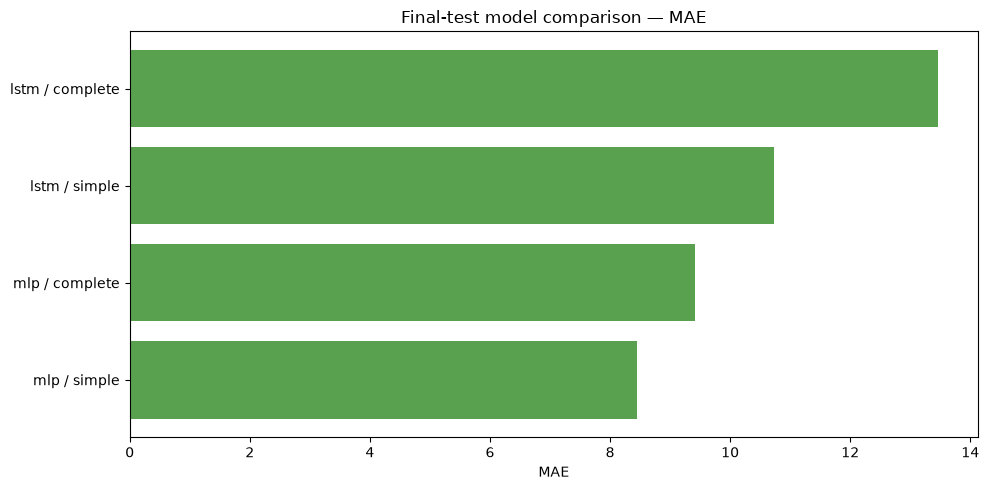

In [8]:
neural_metric_files = sorted(
    list(ARTIFACT_DIRS['metrics'].glob('mlp_*_test_metrics.json'))
    + list(ARTIFACT_DIRS['metrics'].glob('lstm_*_test_metrics.json'))
)
if not neural_metric_files:
    raise RuntimeError('Execute e salve ao menos um experimento neural antes da comparação')

persisted_neural_metrics = [
    json.loads(path.read_text(encoding='utf-8'))
    for path in neural_metric_files
]
neural_comparison = pd.DataFrame(persisted_neural_metrics)
neural_comparison['Coverage'] = 1.0
neural_comparison = neural_comparison.sort_values(['MAE', 'RMSE']).reset_index(drop=True)
neural_comparison.to_csv(
    ARTIFACT_DIRS['comparisons'] / 'neural_model_comparison.csv',
    index=False,
)
display(neural_comparison[[
    'Model', 'Dataset', 'Rows', 'MAE', 'RMSE', 'R2',
    'PoissonDeviance', 'OptimizationSeconds', 'RefitSeconds',
    'TotalExperimentSeconds',
]])

figure, _ = plot_model_comparison(neural_comparison, metric='MAE')
figure.savefig(
    ARTIFACT_DIRS['comparisons'] / 'neural_model_comparison.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

## 9. Atualização da comparação geral

Os resultados neurais persistidos são combinados com Random Forest, XGBoost e baseline já presentes no projeto.

,Model,Dataset,MAE,RMSE,R2,PoissonDeviance,Coverage
0,mlp,simple,8.448963,15.858206,-0.053861,24.383145,1.000000
1,xgboost,complete,8.816675,15.047539,0.051132,12.762339,1.000000
2,xgboost,simple,9.267219,15.302343,0.018725,13.147575,1.000000
3,mlp,complete,9.414437,17.771295,-0.323467,37.354761,1.000000
4,lstm,simple,10.728227,18.252151,-0.396057,118.852478,1.000000
5,random_forest,simple,10.994128,16.745544,-0.175097,14.639403,1.000000
6,random_forest,complete,11.155468,16.337231,-0.118489,14.460354,1.000000
7,lag1_baseline,target_only,11.462185,20.425310,-0.742894,62.746970,0.994429
8,lstm,complete,13.455813,20.002133,-0.676593,44.435449,1.000000


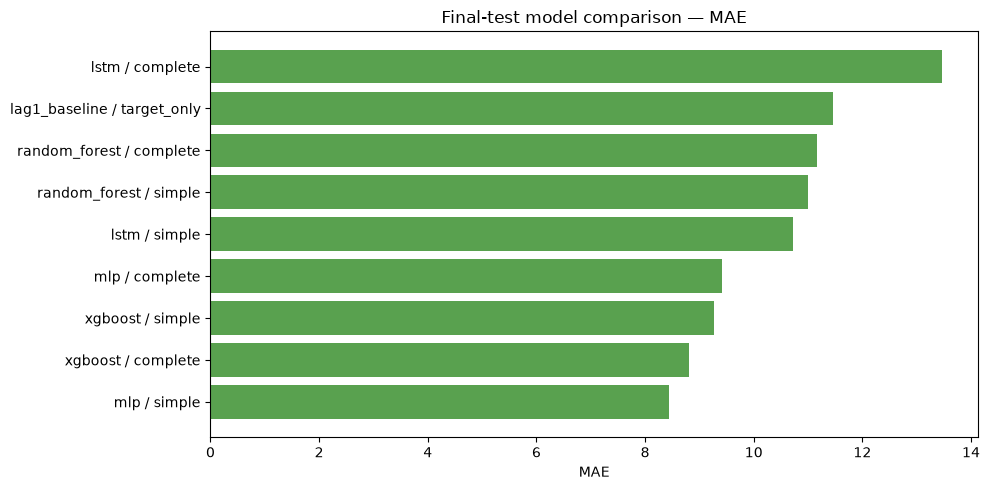

In [9]:
comparison_path = ARTIFACT_DIRS['comparisons'] / 'model_comparison.csv'
if comparison_path.exists():
    previous_comparison = pd.read_csv(comparison_path)
    previous_comparison = previous_comparison.loc[
        ~previous_comparison['Model'].isin(['mlp', 'lstm'])
    ]
else:
    previous_comparison = pd.DataFrame()

comparison = pd.concat(
    [previous_comparison, neural_comparison],
    ignore_index=True,
    sort=False,
).sort_values(['MAE', 'RMSE']).reset_index(drop=True)
comparison.to_csv(comparison_path, index=False)
display(comparison[[
    'Model', 'Dataset', 'MAE', 'RMSE', 'R2',
    'PoissonDeviance', 'Coverage',
]])

figure, _ = plot_model_comparison(comparison, metric='MAE')
figure.savefig(
    ARTIFACT_DIRS['comparisons'] / 'model_comparison.png',
    dpi=150,
    bbox_inches='tight',
)
plt.show()

## 10. Manifesto dos artefatos neurais

In [10]:
manifest_rows = []
for section, directory in ARTIFACT_DIRS.items():
    for path in sorted(directory.glob('*')):
        if path.is_file() and path.name.startswith(('mlp_', 'lstm_', 'neural_')):
            manifest_rows.append({
                'Section': section,
                'File': path.name,
                'Path': path.as_posix(),
                'Bytes': path.stat().st_size,
            })

artifact_manifest = pd.DataFrame(manifest_rows).sort_values(
    ['Section', 'File']
).reset_index(drop=True)
manifest_path = ARTIFACT_DIRS['comparisons'] / 'neural_artifact_manifest.csv'
artifact_manifest.to_csv(manifest_path, index=False)
display(artifact_manifest)
print(f'Artifact manifest saved to: {manifest_path}')

,Section,File,Path,Bytes
0,comparisons,neural_artifact_manifest.csv,results/modeling/comparisons/neural_artifact_m...,4600
1,comparisons,neural_model_comparison.csv,results/modeling/comparisons/neural_model_comp...,1152
2,comparisons,neural_model_comparison.png,results/modeling/comparisons/neural_model_comp...,23927
3,metadata,lstm_complete_metadata.json,results/modeling/metadata/lstm_complete_metada...,2151
4,metadata,lstm_simple_metadata.json,results/modeling/metadata/lstm_simple_metadata...,1523
5,metadata,mlp_complete_metadata.json,results/modeling/metadata/mlp_complete_metadat...,2123
6,metadata,mlp_simple_metadata.json,results/modeling/metadata/mlp_simple_metadata....,1481
7,metadata,neural_experiment_protocol.json,results/modeling/metadata/neural_experiment_pr...,1277
8,metrics,lstm_complete_test_metrics.json,results/modeling/metrics/lstm_complete_test_me...,530
9,metrics,lstm_complete_test_seeds.csv,results/modeling/metrics/lstm_complete_test_se...,713


Artifact manifest saved to: results\modeling\comparisons\neural_artifact_manifest.csv


## Saídas

Cada treinamento persiste imediatamente checkpoint, metadados, métricas finais e por semente, previsões, resíduos e tabelas de validação. A comparação e o manifesto podem ser reconstruídos dos arquivos salvos mesmo após reiniciar o kernel.